In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
import polars as pl

print("Environment is ready!")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")

Environment is ready!
NumPy: 2.4.6
Pandas: 3.1.1


In [2]:
from pathlib import Path                      # làm việc với đường dẫn file
from scipy import stats                       # kiểm định thống kê (chi bình phương, z)
from sklift.datasets import fetch_hillstrom   # hàm tải bộ Hillstrom của scikit-uplift

SEED = 42                                     # cố định seed để kết quả lặp lại được
np.random.seed(SEED)

ROOT = Path.cwd().resolve()                   # thư mục notebook đang chạy
while not (ROOT / "environment.yml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent                        # đi ngược lên đến thư mục gốc repo
RAW = ROOT / "data" / "raw"                   # nơi lưu dữ liệu gốc (đã .gitignore)
EXP = "hillstrom_eda"                                    # tên thí nghiệm = tên thư mục con
FIG = ROOT / "lab" / "reports" / "figures" / EXP         # ảnh của notebook này
TAB = ROOT / "lab" / "reports" / "tables" / EXP          # bảng của notebook này
for p in (RAW, FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)      # tạo thư mục nếu chưa có

sns.set_theme(style="whitegrid")              # kiểu nền biểu đồ
print("ROOT =", ROOT)                         # kiểm tra ROOT đúng là uplift-promotion-dsr

ROOT = /Volumes/PROJECTS/uplift-promotion-dsr


/opt/anaconda3/envs/uplift-promotion-dsr/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
bunches = {}
for col in ["visit", "conversion", "spend"]:                  # mỗi lần gọi chỉ trả về 1 biến kết quả
    bunches[col] = fetch_hillstrom(target_col=col, data_home=str(RAW))

base = bunches["visit"]
df = base.data.copy()                                         # các biến trước can thiệp (đặc trưng)
df["segment"] = base.treatment.astype(str).values             # nhóm email gốc của Hillstrom
for col in ["visit", "conversion", "spend"]:
    df[col] = bunches[col].target.values                      # ghép 3 biến kết quả vào cùng bảng

def norm(s):                                                  # chuẩn hóa tên nhóm cho ngắn
    s = s.lower()
    if "women" in s:                                          # phải kiểm tra "women" trước vì "women" chứa "men"
        return "women"
    if "men" in s:
        return "men"
    return "control"

df["group"] = df["segment"].map(norm)                         # men / women / control
print(pd.crosstab(df["segment"], df["group"]))                # kiểm tra: mỗi segment gốc phải rơi đúng 1 nhóm

group          control    men  women
segment                             
Mens E-Mail          0  21307      0
No E-Mail        21306      0      0
Womens E-Mail        0      0  21387


In [4]:
print("Số dòng, số cột:", df.shape)            # kỳ vọng khoảng 64.000 dòng
df.info()                                      # kiểu dữ liệu và số giá trị không rỗng từng cột
display(df.head())                             # xem 5 dòng đầu
print(df.isna().sum())                         # số giá trị thiếu từng cột
print("Dòng trùng nhau:", df.duplicated().sum())   # không có ID khách nên trùng nhau chưa chắc là lỗi
display(df.describe(include="all").T)          # thống kê mô tả cho mọi cột

Số dòng, số cột: (64000, 13)
<class 'pandas.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  str    
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  str    
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  str    
 8   segment          64000 non-null  str    
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
 12  group            64000 non-null  str    
dtypes: float64(2), int64(6), str(5)
memory usage: 8.9 MB


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,group
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0,women
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0,control
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0,women
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0,men
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0,women


recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
group              0
dtype: int64
Dòng trùng nhau: 6562


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
recency,64000.0,NaN,NaN,NaN,5.763734,3.507592,1.0,2.0,6.0,9.0,12.0
history_segment,64000,7,1) $0 - $100,22970,NaN,NaN,NaN,NaN,NaN,NaN,NaN
history,64000.0,NaN,NaN,NaN,242.085656,256.158608,29.99,64.66,158.11,325.6575,3345.93
mens,64000.0,NaN,NaN,NaN,0.551031,0.497393,0.0,0.0,1.0,1.0,1.0
womens,64000.0,NaN,NaN,NaN,0.549719,0.497526,0.0,0.0,1.0,1.0,1.0
zip_code,64000,3,Surburban,28776,NaN,NaN,NaN,NaN,NaN,NaN,NaN
newbie,64000.0,NaN,NaN,NaN,0.50225,0.499999,0.0,0.0,1.0,1.0,1.0
channel,64000,3,Web,28217,NaN,NaN,NaN,NaN,NaN,NaN,NaN
segment,64000,3,Womens E-Mail,21387,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visit,64000.0,NaN,NaN,NaN,0.146781,0.35389,0.0,0.0,0.0,0.0,1.0


In [5]:
dist = df["group"].value_counts().rename("n").to_frame()   # đếm khách mỗi nhóm
dist["share"] = dist["n"] / len(df)                        # tỷ lệ mỗi nhóm
display(dist)                                              # kỳ vọng mỗi nhóm khoảng 1/3
dist.to_csv(TAB / "hillstrom_group_distribution.csv")      # lưu bảng

,n,share
group,,
women,21387,0.334172
men,21307,0.332922
control,21306,0.332906


,men vs control,women vs control
recency,0.007,0.005
history,0.008,0.007
mens,-0.005,-0.009
womens,0.008,0.005
newbie,-0.001,0.003
history_segment_1) $0 - $100,0.011,-0.001
history_segment_2) $100 - $200,-0.016,-0.014
history_segment_3) $200 - $350,0.005,0.011
history_segment_4) $350 - $500,-0.004,0.009
history_segment_5) $500 - $750,-0.010,0.001


Biến có |SMD| > 0,1: 0


,variable,test,p_value
0,mens,chi2,0.6717
1,womens,chi2,0.7289
2,newbie,chi2,0.9339
3,history_segment,chi2,0.3580
4,zip_code,chi2,0.5795
5,channel,chi2,0.4580
6,recency,kruskal,0.7941
7,history,kruskal,0.6669


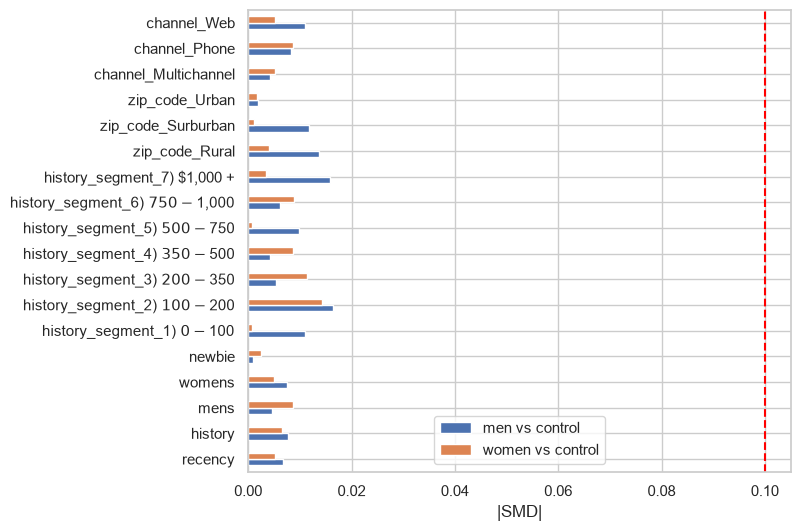

In [6]:
num_cols = ["recency", "history"]                   # biến số liên tục
bin_cols = ["mens", "womens", "newbie"]             # biến 0/1
cat_cols = ["history_segment", "zip_code", "channel"]   # biến phân loại

# đổi biến phân loại thành các cột 0/1 để tính SMD cho từng mức
X = pd.get_dummies(df[num_cols + bin_cols + cat_cols], columns=cat_cols, dtype=float)

rows = {}
for g in ["men", "women"]:
    a = X[df["group"] == g]                         # nhóm nhận email g
    b = X[df["group"] == "control"]                 # nhóm đối chứng
    rows[f"{g} vs control"] = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)   # SMD
smd = pd.DataFrame(rows)
display(smd.round(3))                               # |SMD| < 0,1 thường coi là cân bằng
print("Biến có |SMD| > 0,1:", (smd.abs() > 0.1).any(axis=1).sum())

fig, ax = plt.subplots(figsize=(7, 6))
smd.abs().plot.barh(ax=ax)                          # biểu đồ |SMD| mỗi biến
ax.axvline(0.1, color="red", ls="--")               # ngưỡng 0,1
ax.set_xlabel("|SMD|")
fig.savefig(FIG / "hillstrom_smd.png", dpi=150, bbox_inches="tight")

chi_rows = []
for v in bin_cols + cat_cols:                       # biến phân loại: kiểm định chi bình phương
    ct = pd.crosstab(df[v], df["group"])            # bảng chéo biến x nhóm
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    chi_rows.append({"variable": v, "test": "chi2", "p_value": p})
for v in num_cols:                                  # biến số: kiểm định Kruskal-Wallis giữa 3 nhóm
    h, p = stats.kruskal(*[df.loc[df["group"] == g, v] for g in ["men", "women", "control"]])
    chi_rows.append({"variable": v, "test": "kruskal", "p_value": p})
balance = pd.DataFrame(chi_rows)
display(balance.round(4))                           # p lớn = không thấy khác biệt giữa các nhóm
smd.to_csv(TAB / "hillstrom_smd.csv")
balance.to_csv(TAB / "hillstrom_balance_tests.csv", index=False)

n    mean  ci_low  ci_high
outcome    group                                    
visit      control  21306.0  0.1062  0.1020   0.1103
           men      21307.0  0.1828  0.1776   0.1879
           women    21387.0  0.1514  0.1466   0.1562
conversion control  21306.0  0.0057  0.0047   0.0067
           men      21307.0  0.0125  0.0110   0.0140
           women    21387.0  0.0088  0.0076   0.0101
spend      control  21306.0  0.6528  0.4972   0.8084
           men      21307.0  1.4226  1.1842   1.6610
           women    21387.0  1.0772  0.8746   1.2798

Số đơn conversion mỗi nhóm:
group
control    122
men        267
women      189
Name: conversion, dtype: int64


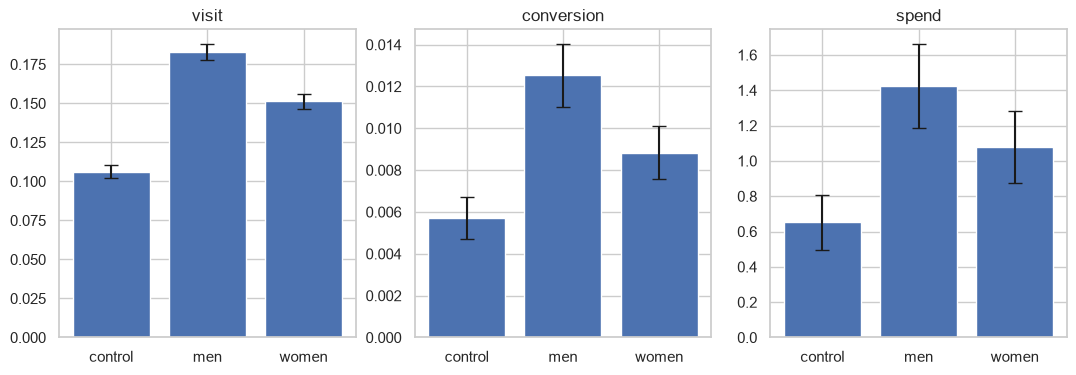

In [7]:
outcomes = ["visit", "conversion", "spend"]

def mean_ci(x):                                     # trung bình và khoảng tin cậy 95% (xấp xỉ chuẩn)
    n = len(x)
    m = x.mean()
    se = x.std(ddof=1) / np.sqrt(n)                 # sai số chuẩn
    return pd.Series({"n": n, "mean": m, "ci_low": m - 1.96 * se, "ci_high": m + 1.96 * se})

res = pd.concat(
    {o: df.groupby("group")[o].apply(mean_ci).unstack() for o in outcomes},
    names=["outcome"],
)
display(res.round(4))
res.to_csv(TAB / "hillstrom_outcomes_by_group.csv")

print("Số đơn conversion mỗi nhóm:")
print(df.groupby("group")["conversion"].sum())      # số sự kiện thật; nhỏ thì tín hiệu uplift yếu

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
order = ["control", "men", "women"]
for ax, o in zip(axes, outcomes):
    t = res.loc[o].loc[order]                       # bảng của biến kết quả o theo thứ tự nhóm
    ax.bar(order, t["mean"], yerr=[t["mean"] - t["ci_low"], t["ci_high"] - t["mean"]], capsize=5)
    ax.set_title(o)
fig.savefig(FIG / "hillstrom_outcomes.png", dpi=150, bbox_inches="tight")

In [8]:
def ate(y1, y0):                                    # chênh lệch trung bình và khoảng tin cậy 95%
    d = y1.mean() - y0.mean()
    se = np.sqrt(y1.var(ddof=1) / len(y1) + y0.var(ddof=1) / len(y0))
    p = 2 * (1 - stats.norm.cdf(abs(d / se)))       # p-value hai phía theo kiểm định z
    return d, d - 1.96 * se, d + 1.96 * se, p

g = df["group"]
pairs = {
    "men vs control": (g == "men", g == "control"),
    "women vs control": (g == "women", g == "control"),
    "any email vs control": (g != "control", g == "control"),   # gộp hai loại email
}
out = []
for name, (t, c) in pairs.items():
    for o in outcomes:
        d, lo, hi, p = ate(df.loc[t, o], df.loc[c, o])
        out.append({"pair": name, "outcome": o, "ATE": d, "ci_low": lo, "ci_high": hi, "p_value": p})
ate_df = pd.DataFrame(out)
display(ate_df.round(4))
ate_df.to_csv(TAB / "hillstrom_ate.csv", index=False)

,pair,outcome,ATE,ci_low,ci_high,p_value
0,men vs control,visit,0.0766,0.0700,0.0832,0.0000
1,men vs control,conversion,0.0068,0.0050,0.0086,0.0000
2,men vs control,spend,0.7698,0.4851,1.0545,0.0000
3,women vs control,visit,0.0452,0.0389,0.0516,0.0000
4,women vs control,conversion,0.0031,0.0015,0.0047,0.0002
5,women vs control,spend,0.4244,0.1690,0.6799,0.0011
6,any email vs control,visit,0.0609,0.0554,0.0663,0.0000
7,any email vs control,conversion,0.0050,0.0035,0.0064,0.0000
8,any email vs control,spend,0.5968,0.3762,0.8174,0.0000


Tỷ lệ visit tổng: 0.1468
Tỷ lệ conversion tổng: 0.009
Spend = 0: 0.991
conversion trùng với spend > 0: 1.0


count    578.000000
mean     116.363547
std      107.871537
min       29.990000
25%       32.272500
50%       80.795000
75%      153.350000
max      499.000000
Name: spend, dtype: float64

Độ lệch (skewness) của spend khi > 0: 1.76


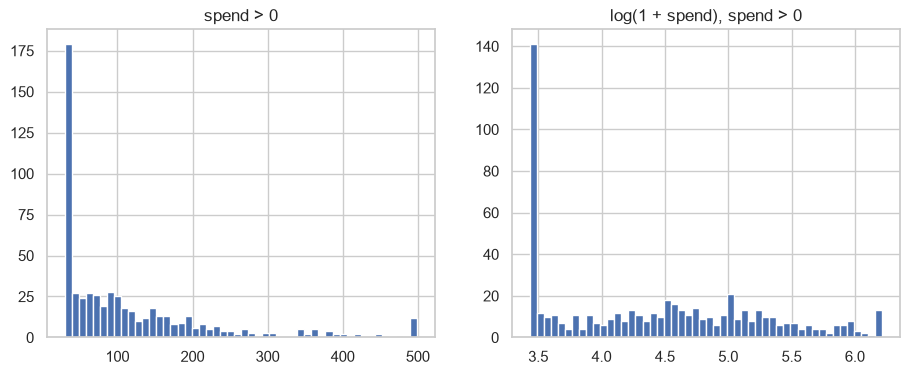

In [9]:
print("Tỷ lệ visit tổng:", round(df["visit"].mean(), 4))
print("Tỷ lệ conversion tổng:", round(df["conversion"].mean(), 4))
print("Spend = 0:", round((df["spend"] == 0).mean(), 4))                 # nhiều giá trị 0
print("conversion trùng với spend > 0:", ((df["spend"] > 0) == (df["conversion"] == 1)).mean())

s = df.loc[df["spend"] > 0, "spend"]                                    # chỉ xét khách có mua
display(s.describe())
print("Độ lệch (skewness) của spend khi > 0:", round(s.skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(s, bins=50)                         # phân phối spend gốc
axes[0].set_title("spend > 0")
axes[1].hist(np.log1p(s), bins=50)               # sau khi lấy log(1 + spend)
axes[1].set_title("log(1 + spend), spend > 0")
fig.savefig(FIG / "hillstrom_spend_distribution.png", dpi=150, bbox_inches="tight")